# Лабораторная работа: Detectarea anomaliilor — обнаружение аномалий

## Цель
Научиться находить объекты недвижимости, которые **заметно отличаются от основной массы** данных, сравнить несколько алгоритмов и понять, что именно делает объект «необычным».

## Задачи
1. Подготовить данные, не удаляя заранее выбросы.
2. Применить простые методы (Z-score, IQR) и объяснить их ограничения.
3. Применить **Isolation Forest**, **Local Outlier Factor (LOF)** и **One-Class SVM**, исследовать параметры.
4. Сравнить методы *без истинных меток*: по пересечению, стабильности и отличию найденных объектов от основной массы; отдельно — на **искусственно добавленных** аномалиях.
5. Разобрать несколько найденных объектов и проверить, не вызваны ли они пропусками или ошибками.

> **Важно.** Аномалия — это не обязательно ошибка. Объект может быть реальным, редким или просто дорогим. Алгоритм лишь помечает его как *нетипичный по выбранным признакам*; такие объекты «требуют дополнительной проверки».

**Файл данных:** `real_estate_regression_dataset.csv`. Исходный файл не изменяется. 

## Теория: аномалии и обычные выбросы

**Выброс (outlier)** — значение, далёкое от остальных, чаще всего по *одному* признаку (очень большая площадь).
**Аномалия (anomaly)** — наблюдение, нетипичное в целом, в том числе из-за *сочетания* признаков, каждый из которых по отдельности обычен (например, маленькая площадь при шести спальнях).

**Типы аномалий:**
- *глобальные* — далеко от всех остальных объектов;
- *локальные* — не выделяются на фоне всех данных, но необычны на фоне своих ближайших соседей (например, объект с «обычной» площадью, но в группе, где все объекты гораздо плотнее);
- *контекстные* — необычны в определённом контексте (например, 300 м² для квартиры в центре);
- *коллективные* — необычна группа объектов вместе.

**Обучение без учителя.** Истинных меток «аномалия / не аномалия» у нас нет, поэтому классические accuracy, precision, recall и F1 *неприменимы* (их можно считать только в отдельном эксперименте с искусственно добавленными аномалиями, где метки известны по построению).

**Методы:**
- **Z-score** — сколько стандартных отклонений значение отстоит от среднего.
- **IQR** — значения за пределами «усов» boxplot (1.5 межквартильных размаха от квартилей).
- **Isolation Forest** — случайные деревья «изолируют» объекты случайными разрезами; аномалии изолируются за **малое число разрезов**.
- **LOF** — сравнивает локальную плотность вокруг объекта с плотностью вокруг его соседей; в разреженной области среди плотных соседей — высокий LOF.
- **One-Class SVM** — строит гибкую границу вокруг основной массы данных; всё за границей — аномалия.

## Импорт библиотек и загрузка данных
Используем только `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` — дополнительные библиотеки не нужны. Если чего-то нет: `!pip install pandas numpy matplotlib seaborn scikit-learn`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
RANDOM_STATE = 42

In [2]:
# Данные лежат в папке data/ рядом с папкой notebooks/
DATA_PATH = Path("../data/real_estate_regression_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Файл данных не найден. Проверьте, что он лежит в папке data/.")
print("Файл найден:", DATA_PATH)

# Папка для результатов
OUT_DIR = Path("../outputs/anomaly_detection")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Папка результатов:", OUT_DIR)

df_raw = pd.read_csv(DATA_PATH)       # исходные данные, дальше не изменяются
print("Строк:", df_raw.shape[0], "| Столбцов:", df_raw.shape[1])
df_raw.head()

Файл найден: ../data/real_estate_regression_dataset.csv
Папка результатов: ../outputs/anomaly_detection
Строк: 2840 | Столбцов: 28


,Id,Neighborhood,PropertyType,OverallQual,Condition,RenovationQuality,GrLivArea,LotArea,TotalBsmtSF,Rooms,Bedrooms,Bathrooms,Floor,TotalFloors,YearBuilt,YearRenovated,PropertyAge,GarageType,GarageCars,GarageArea,HeatingType,EnergyEfficiency,DistanceToCenter,HasPool,HasBalcony,CrimeRate,SchoolRating,SalePrice
0,994,GreenPark,Townhouse,9,Average,High,121,154.0,104.0,5,4,2,1,2,2016,2024.0,8,Detached,1,22.0,Electric,98.0,4.8,0,0,4.8,9.1,641900
1,279,Eastgate,House,9,Fair,Medium,90,1227.0,50.0,4,3,3,1,2,1982,2018.0,42,Attached,1,17.0,Gas,97.0,7.7,0,0,3.5,5.4,283500
2,820,OldTown,Apartment,4,Good,Low,104,0.0,0.0,3,2,1,1,5,1992,2024.0,32,NoGarage,0,0.0,Gas,97.0,2.5,0,0,4.6,5.9,365300
3,2700,Eastgate,Apartment,5,Good,Low,80,0.0,0.0,4,1,2,6,10,2012,2024.0,12,Underground,1,30.0,District,100.0,8.4,0,1,5.2,9.5,341200
4,1205,Downtown,House,9,Excellent,Medium,156,583.0,135.0,7,5,3,1,1,2018,2024.0,6,Detached,2,49.0,Electric,100.0,0.3,1,0,7.0,6.7,1238000


## EDA и проверка качества данных
Смотрим типы, пропуски, дубликаты, статистики и распределения; ищем очевидные проблемы качества (невозможные значения, нарушенные логические связи).

In [3]:
info = pd.DataFrame({"тип": df_raw.dtypes, "пропусков": df_raw.isna().sum(),
                     "доля пропусков, %": (df_raw.isna().mean() * 100).round(1), "уникальных": df_raw.nunique()})
print(info.to_string())
print("\nПолных дубликатов:", df_raw.duplicated().sum())

                       тип  пропусков  доля пропусков, %  уникальных
Id                   int64          0                0.0        2800
Neighborhood        object          0                0.0          13
PropertyType        object          0                0.0           6
OverallQual          int64          0                0.0          10
Condition           object        145                5.1           6
RenovationQuality   object        245                8.6           3
GrLivArea            int64          0                0.0         281
LotArea            float64        145                5.1         832
TotalBsmtSF        float64        249                8.8         205
Rooms                int64          0                0.0          10
Bedrooms             int64          0                0.0          11
Bathrooms            int64          0                0.0           7
Floor                int64          0                0.0          19
TotalFloors          int64        

In [4]:
num_all = df_raw.select_dtypes(include="number").columns.drop("Id")
stats = df_raw[num_all].describe().T
stats["skew"] = df_raw[num_all].skew()          # асимметрия: |skew| > 1 — сильный «хвост»
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
OverallQual,2840.0,6.11,1.60,1.0,5.0,6.0,7.0,10.0,-0.03
GrLivArea,2840.0,128.94,59.01,29.0,84.0,120.0,159.0,538.0,1.47
LotArea,2695.0,338.03,556.10,0.0,0.0,221.0,463.5,11197.0,8.49
TotalBsmtSF,2591.0,55.40,56.50,0.0,0.0,53.0,92.0,449.0,1.00
Rooms,2840.0,5.39,1.79,2.0,4.0,5.0,6.0,11.0,0.47
Bedrooms,2840.0,3.42,1.61,1.0,2.0,3.0,4.0,12.0,0.72
Bathrooms,2840.0,2.24,1.05,1.0,1.0,2.0,3.0,7.0,0.73
Floor,2840.0,2.56,3.31,1.0,1.0,1.0,2.0,19.0,2.53
TotalFloors,2840.0,4.77,5.13,1.0,2.0,2.0,7.0,19.0,1.46
YearBuilt,2840.0,1988.79,20.98,1890.0,1975.0,1989.0,2004.0,2024.0,-0.32


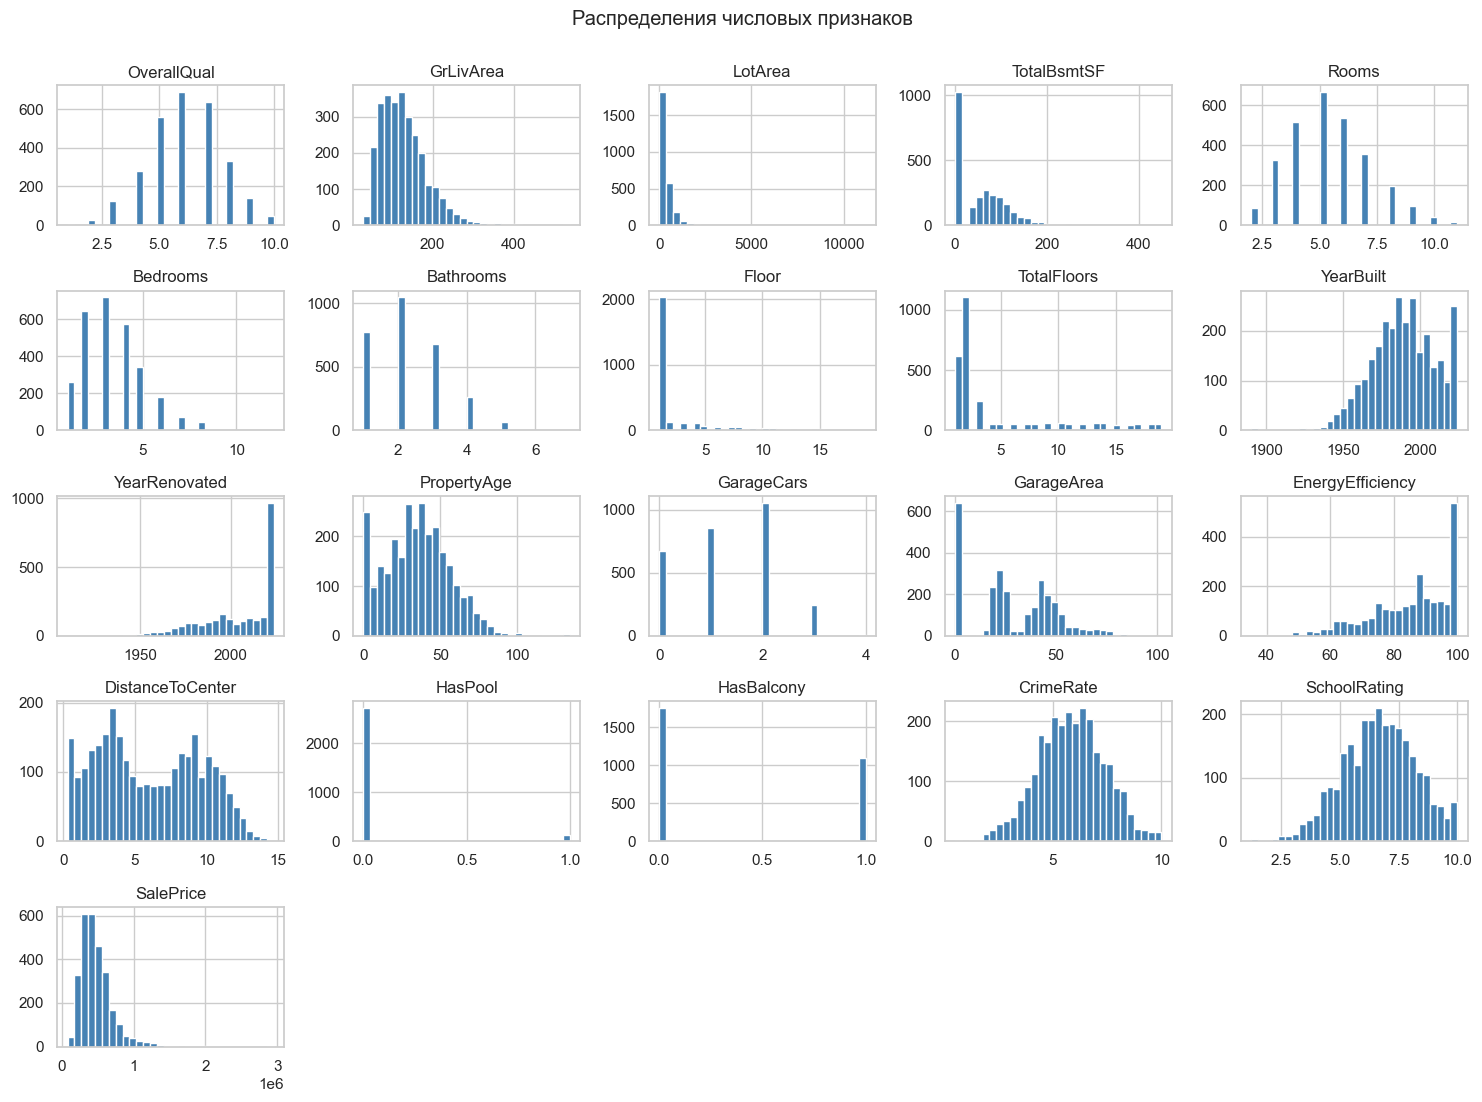

In [5]:
df_raw[num_all].hist(bins=30, figsize=(15, 11), color="steelblue")
plt.suptitle("Распределения числовых признаков", y=1.0)
plt.tight_layout()
plt.show()

In [6]:
# Простые проверки логики данных (очевидные проблемы качества)
checks = {
    "Отрицательные значения (числовые признаки)": int((df_raw[num_all] < 0).any(axis=1).sum()),
    "Комнат меньше, чем спален (Rooms < Bedrooms)": int((df_raw["Rooms"] < df_raw["Bedrooms"]).sum()),
    "Ремонт раньше постройки (YearRenovated < YearBuilt)": int((df_raw["YearRenovated"] < df_raw["YearBuilt"]).sum()),
    "Этаж выше числа этажей (Floor > TotalFloors)": int((df_raw["Floor"] > df_raw["TotalFloors"]).sum()),
    "Гараж без машиномест, но с площадью": int(((df_raw["GarageCars"] == 0) & (df_raw["GarageArea"] > 0)).sum()),
    "Год постройки в будущем (> 2024)": int((df_raw["YearBuilt"] > 2024).sum()),
}
pd.Series(checks, name="нарушений")

Отрицательные значения (числовые признаки)             0
Комнат меньше, чем спален (Rooms < Bedrooms)           4
Ремонт раньше постройки (YearRenovated < YearBuilt)    0
Этаж выше числа этажей (Floor > TotalFloors)           0
Гараж без машиномест, но с площадью                    0
Год постройки в будущем (> 2024)                       0
Name: нарушений, dtype: int64

**Как читать:** если во всех строках нули, явных логических ошибок в данных нет, и «странные» объекты, которые найдут алгоритмы, будут редкими или необычными, а не очевидно сломанными. Сильная асимметрия (`skew`) признаков площади важна для Z-score: он предполагает приблизительно симметричное распределение.

## Подготовка и масштабирование признаков

**Дубликаты** удаляем: копия объекта делает его «не одиноким» (его соседом становится его же копия), что искажает LOF и Isolation Forest.

**Выбросы заранее не удаляем** — иначе мы убрали бы именно то, что исследуем.

**Признаки для поиска аномалий** — 12 числовых характеристик объекта и его окружения: `GrLivArea`, `LotArea`, `TotalBsmtSF`, `Bedrooms`, `Bathrooms`, `OverallQual`, `PropertyAge`, `GarageArea`, `DistanceToCenter`, `EnergyEfficiency`, `CrimeRate`, `SchoolRating`.
- `Id` исключён (номер, не свойство объекта).
- Бинарные `HasPool` и `HasBalcony` исключены: для расстояний и Z-score 0/1 признаки малоосмысленны.
- Дублирующие признаки (`YearBuilt` = копия `PropertyAge`, `Rooms`, `GarageCars`, `YearRenovated`, `Floor`, `TotalFloors`) исключены, чтобы одна и та же информация не учитывалась несколько раз.
- Категории (`PropertyType`, `Neighborhood`, ...) в алгоритмы не передаём (расстояния по ним плохо определены), но используем при разборе объектов.

**Цена `SalePrice`** в основной набор **не включена**: иначе аномалией часто становились бы просто «очень дорогие» объекты. Мы ищем объекты, необычные по *характеристикам*, а цену используем *после* — как дополнительную информацию (в разделе сравнения проверим и вариант с ценой в признаках).

**Пропуски.** Алгоритмы не принимают NaN, поэтому числовые пропуски заполняем медианой. Но у 35% объектов хотя бы один из выбранных признаков пропущен, поэтому запоминаем, *какие значения были заполнены* (`imputed_mask`), чтобы потом проверить, не стали ли аномалии следствием заполнения.

**Масштабирование.** Isolation Forest не зависит от масштаба, а LOF и One-Class SVM — зависят (они считают расстояния). Используем `RobustScaler` (медиана и IQR), устойчивый к выбросам; влияние масштаба проверим отдельно.

In [7]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Удалено дубликатов: {len(df_raw) - len(df)}. Осталось объектов: {len(df)}")

features = ["GrLivArea", "LotArea", "TotalBsmtSF", "Bedrooms", "Bathrooms", "OverallQual",
            "PropertyAge", "GarageArea", "DistanceToCenter", "EnergyEfficiency", "CrimeRate", "SchoolRating"]

imputed_mask = df[features].isna()                         # где значения были пропущены
X_imp = df[features].fillna(df[features].median())          # заполнение медианой
print("Объектов с хотя бы одним пропуском среди выбранных признаков:", int(imputed_mask.any(axis=1).sum()),
      f"({imputed_mask.any(axis=1).mean() * 100:.1f}%)")

scaler = RobustScaler().fit(X_imp)
X_rs = scaler.transform(X_imp)                             # масштабированные признаки для LOF и One-Class SVM
print("Матрица признаков:", X_rs.shape)

Удалено дубликатов: 40. Осталось объектов: 2800
Объектов с хотя бы одним пропуском среди выбранных признаков: 972 (34.7%)
Матрица признаков: (2800, 12)


## Z-score и IQR как базовые методы
**Z-score** = `(x − среднее) / стандартное отклонение`: насколько «сигм» значение отстоит от среднего. Порог |Z| > 3 считается экстремальным. *Ограничения:* среднее и стандартное отклонение сами искажаются выбросами; для скошенных распределений даёт много ложных срабатываний на «хвосте»; смотрит на каждый признак отдельно и не видит необычных сочетаний.

**IQR:** границы `Q1 − 1.5·IQR` и `Q3 + 1.5·IQR` (усы boxplot). Устойчивее к выбросам, чем Z-score, но тоже работает по одному признаку.

In [8]:
# Z-score по каждому признаку
Z = (X_imp - X_imp.mean()) / X_imp.std()
z_flags = Z.abs() > 3

# IQR по каждому признаку
q1, q3 = X_imp.quantile(0.25), X_imp.quantile(0.75)
iqr = q3 - q1
iqr_flags = (X_imp < q1 - 1.5 * iqr) | (X_imp > q3 + 1.5 * iqr)

summary = pd.DataFrame({"Z-score (|Z|>3)": z_flags.sum(), "IQR (1.5·IQR)": iqr_flags.sum()})
summary.loc["ИТОГО объектов (хотя бы по одному признаку)"] = [int(z_flags.any(axis=1).sum()), int(iqr_flags.any(axis=1).sum())]
summary

,Z-score (|Z|>3),IQR (1.5·IQR)
GrLivArea,34,65
LotArea,24,121
TotalBsmtSF,27,22
Bedrooms,5,51
Bathrooms,9,4
OverallQual,4,4
PropertyAge,11,14
GarageArea,6,12
DistanceToCenter,0,0
EnergyEfficiency,24,42


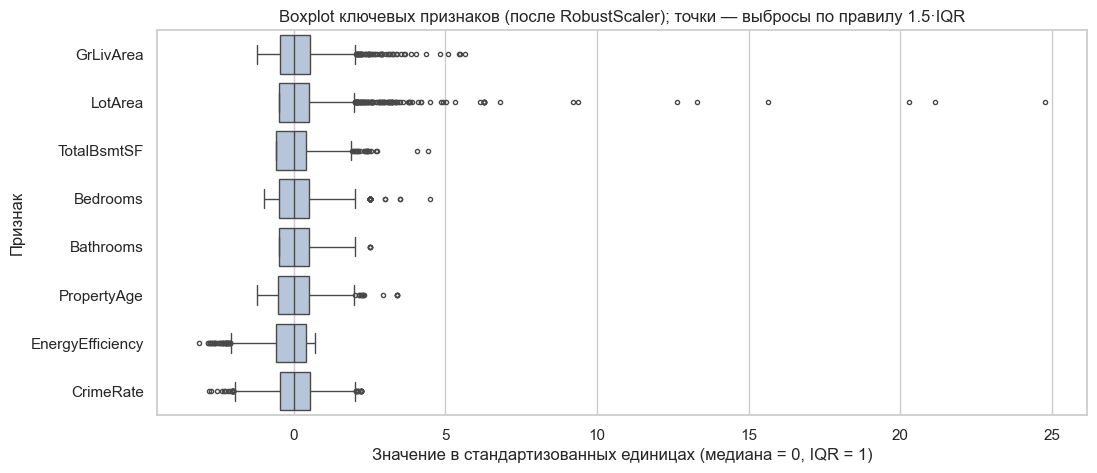

In [9]:
# Boxplot ключевых признаков (в масштабе RobustScaler, чтобы признаки были сопоставимы)
key = ["GrLivArea", "LotArea", "TotalBsmtSF", "Bedrooms", "Bathrooms", "PropertyAge", "EnergyEfficiency", "CrimeRate"]
Xk = pd.DataFrame(X_rs, columns=features)[key]
plt.figure(figsize=(12, 5))
sns.boxplot(data=Xk, orient="h", color="lightsteelblue", fliersize=3)
plt.title("Boxplot ключевых признаков (после RobustScaler); точки — выбросы по правилу 1.5·IQR")
plt.xlabel("Значение в стандартизованных единицах (медиана = 0, IQR = 1)")
plt.ylabel("Признак")
plt.show()

In [10]:
# Сравнение Z-score и IQR: пересечение и разница
zf, qf = z_flags.any(axis=1).values, iqr_flags.any(axis=1).values
print(f"Z-score: {zf.sum()} объектов ({zf.mean() * 100:.1f}%) | IQR: {qf.sum()} ({qf.mean() * 100:.1f}%)")
print(f"Оба метода: {(zf & qf).sum()} | только Z-score: {(zf & ~qf).sum()} | только IQR: {(qf & ~zf).sum()}")
print(f"Jaccard (мера сходства множеств): {(zf & qf).sum() / (zf | qf).sum():.2f}")

Z-score: 126 объектов (4.5%) | IQR: 278 (9.9%)
Оба метода: 124 | только Z-score: 2 | только IQR: 154
Jaccard (мера сходства множеств): 0.44


**Как читать:** IQR обычно помечает больше объектов, чем Z-score при пороге 3, потому что его границы уже. Оба метода работают с *отдельными* признаками: они найдут «очень большой участок», но не «маленькую квартиру с шестью спальнями», где каждое значение само по себе обычное. Это покажет эксперимент с искусственными аномалиями ниже.

## Isolation Forest
**Принцип изоляции:** строим много случайных деревьев; на каждом шаге случайно выбираем признак и случайный порог разреза. «Типичный» объект в плотной области надо отделить многими разрезами, а нетипичный изолируется за несколько. Средняя глубина изоляции превращается в **anomaly score**.

**Параметры:** `n_estimators=300` (число деревьев), `contamination` — **ожидаемая доля аномалий**, а не известная истинная. Она лишь задаёт порог: чем выше, тем больше объектов будет помечено. `random_state=42` фиксирует случайность.

In [11]:
CONT = 0.05      # ожидаемая доля аномалий (допущение для сравнения методов, а не известная истина)

iso = IsolationForest(n_estimators=300, contamination=CONT, random_state=RANDOM_STATE).fit(X_rs)
iso_flag = iso.predict(X_rs) == -1                 # True — аномалия
iso_score = -iso.score_samples(X_rs)               # знак изменён: чем БОЛЬШЕ, тем аномальнее
print(f"Isolation Forest: помечено {iso_flag.sum()} объектов ({iso_flag.mean() * 100:.1f}%)")
print("Диапазон anomaly score:", iso_score.min().round(3), "…", iso_score.max().round(3))

Isolation Forest: помечено 140 объектов (5.0%)
Диапазон anomaly score: 0.391 … 0.651


In [12]:
# Параметр contamination: как меняется число аномалий и насколько совпадают наборы
base = iso_flag
rows = []
for c in (0.01, 0.02, 0.05, 0.10):
    m = IsolationForest(n_estimators=300, contamination=c, random_state=RANDOM_STATE).fit(X_rs)
    f = m.predict(X_rs) == -1
    rows.append({"contamination": c, "помечено": int(f.sum()), "доля, %": round(f.mean() * 100, 1),
                 "входят в набор при 0.05": f"{(f & base).sum()} из {f.sum()}"})
pd.DataFrame(rows)

,contamination,помечено,"доля, %",входят в набор при 0.05
0,0.01,28,1.0,28 из 28
1,0.02,56,2.0,56 из 56
2,0.05,140,5.0,140 из 140
3,0.10,280,10.0,140 из 280


In [13]:
# Стабильность относительно случайности: 5 разных random_state, один и тот же contamination
def jaccard(a, b):
    return (a & b).sum() / (a | b).sum()

sets = []
for seed in range(5):
    m = IsolationForest(n_estimators=300, contamination=CONT, random_state=seed).fit(X_rs)
    sets.append(m.predict(X_rs) == -1)
pair = [jaccard(a, b) for a, b in combinations(sets, 2)]
print(f"Средний Jaccard между запусками с разными random_state: {np.mean(pair):.2f} (min {np.min(pair):.2f}, max {np.max(pair):.2f})")
print("Объектов, помеченных во всех 5 запусках:", int(np.logical_and.reduce(sets).sum()), "| хотя бы в одном:", int(np.logical_or.reduce(sets).sum()))

Средний Jaccard между запусками с разными random_state: 0.77 (min 0.74, max 0.81)
Объектов, помеченных во всех 5 запусках: 105 | хотя бы в одном: 181


**Как читать:** `contamination` только сдвигает порог (при росте значения набор «наращивается» теми же самыми объектами в порядке убывания score). Если Jaccard между запусками высокий, результат устойчив к случайности деревьев; объекты, попадающие во все запуски, — самые надёжные кандидаты. Score сам по себе не вероятность и не «степень ошибочности»: он лишь ранжирует объекты по нетипичности.

## Local Outlier Factor (LOF)
**Идея локальной плотности:** для каждого объекта смотрим на его `n_neighbors` ближайших соседей и сравниваем плотность вокруг объекта с плотностью вокруг его соседей. LOF ≈ 1 — объект в такой же плотности, как соседи; **LOF ≫ 1** — объект гораздо «разреженнее» своих соседей, то есть локальная аномалия.

**Почему LOF находит то, что не видят глобальные методы:** объект может быть не далёк от общего центра данных, но расположен в «пустоте» среди плотной группы (или, наоборот, быть частью небольшой, но плотной группы, и тогда он не аномален локально, хотя глобально далёк).

**Параметр `n_neighbors`:** малое значение — чувствительность к мелкому шуму; большое — более «глобальная» оценка. Исследуем несколько значений.

In [14]:
lof_results = {}
for k in (10, 20, 35, 50, 100):
    m = LocalOutlierFactor(n_neighbors=k, contamination=CONT)
    flag = m.fit_predict(X_rs) == -1
    lof_results[k] = {"flag": flag, "score": -m.negative_outlier_factor_}     # score ≈ LOF: чем больше, тем аномальнее

K_LOF = 20
lof_flag, lof_score = lof_results[K_LOF]["flag"], lof_results[K_LOF]["score"]
print(f"LOF (n_neighbors={K_LOF}): помечено {lof_flag.sum()} объектов ({lof_flag.mean() * 100:.1f}%)")

# Сравнение настроек: Jaccard между наборами аномалий
ks = list(lof_results)
jt = pd.DataFrame([[jaccard(lof_results[a]["flag"], lof_results[b]["flag"]) for b in ks] for a in ks], index=ks, columns=ks).round(2)
jt.index.name = "n_neighbors"
jt

LOF (n_neighbors=20): помечено 140 объектов (5.0%)


,10,20,35,50,100
n_neighbors,,,,,
10,1.00,0.64,0.56,0.51,0.44
20,0.64,1.00,0.78,0.73,0.61
35,0.56,0.78,1.00,0.88,0.71
50,0.51,0.73,0.88,1.00,0.76
100,0.44,0.61,0.71,0.76,1.00


**Как читать:** здесь доля помеченных объектов задана `contamination`, поэтому число одинаково при всех `n_neighbors`; различается *состав*. Чем ниже Jaccard между соседними настройками, тем сильнее результат зависит от размера окрестности. Для основного эксперимента берём `n_neighbors=20`.

## One-Class SVM
**Принцип:** алгоритм учится описывать «нормальную» область: строит гибкую границу, охватывающую основную массу данных (в пространстве, заданном RBF-ядром), всё вне границы — аномалия. Обучается на всех данных, предполагая, что аномалий в них мало.

**Параметры:**
- `nu` ∈ (0, 1] — верхняя граница доли объектов вне границы (и нижняя граница доли опорных векторов); примерно задаёт долю аномалий.
- `gamma` — «резкость» ядра: большая `gamma` — очень извилистая граница по малым областям (много объектов вне неё), малая — гладкая, почти эллипсоидальная.

**Вычислительная сложность.** One-Class SVM масштабируется хуже остальных (примерно квадратично по числу объектов). Для 2800 объектов и 12 признаков он работает за секунды, поэтому подвыборка **не нужна** — используем все данные; для сотен тысяч строк пришлось бы брать подвыборку или другой метод. Сетку параметров делаем небольшой.

In [15]:
import time
rows = []
oc_results = {}
for nu in (0.02, 0.05, 0.10):
    for gamma in ("scale", 0.005, 0.05):
        t0 = time.perf_counter()
        m = OneClassSVM(nu=nu, gamma=gamma, kernel="rbf").fit(X_rs)
        flag = m.predict(X_rs) == -1
        oc_results[(nu, gamma)] = {"flag": flag, "score": -m.decision_function(X_rs)}
        rows.append({"nu": nu, "gamma": gamma, "помечено": int(flag.sum()), "доля, %": round(flag.mean() * 100, 1),
                     "время, сек": round(time.perf_counter() - t0, 2)})
pd.DataFrame(rows)

,nu,gamma,помечено,"доля, %","время, сек"
0,0.02,scale,64,2.3,0.02
1,0.02,0.005,58,2.1,0.01
2,0.02,0.05,58,2.1,0.01
3,0.05,scale,149,5.3,0.03
4,0.05,0.005,140,5.0,0.02
5,0.05,0.05,139,5.0,0.02
6,0.10,scale,279,10.0,0.05
7,0.10,0.005,282,10.1,0.05
8,0.10,0.05,279,10.0,0.05


In [16]:
NU, GAMMA = 0.05, "scale"
oc_flag, oc_score = oc_results[(NU, GAMMA)]["flag"], oc_results[(NU, GAMMA)]["score"]
print(f"One-Class SVM (nu={NU}, gamma={GAMMA}): помечено {oc_flag.sum()} объектов ({oc_flag.mean() * 100:.1f}%)")
gamma_scale = 1 / (X_rs.shape[1] * X_rs.var())
print(f"Значение gamma='scale' для этих данных: {gamma_scale:.4f}")

# Стабильность: сходство с основной настройкой
for key, v in oc_results.items():
    if key != (NU, GAMMA):
        print(f"nu={key[0]}, gamma={key[1]}: Jaccard с основной настройкой = {jaccard(v['flag'], oc_flag):.2f}")

One-Class SVM (nu=0.05, gamma=scale): помечено 149 объектов (5.3%)
Значение gamma='scale' для этих данных: 0.1359
nu=0.02, gamma=scale: Jaccard с основной настройкой = 0.42
nu=0.02, gamma=0.005: Jaccard с основной настройкой = 0.35
nu=0.02, gamma=0.05: Jaccard с основной настройкой = 0.39
nu=0.05, gamma=0.005: Jaccard с основной настройкой = 0.47
nu=0.05, gamma=0.05: Jaccard с основной настройкой = 0.66
nu=0.1, gamma=scale: Jaccard с основной настройкой = 0.53
nu=0.1, gamma=0.005: Jaccard с основной настройкой = 0.43
nu=0.1, gamma=0.05: Jaccard с основной настройкой = 0.52


**Как читать:** при `nu=0.02/0.05/0.10` число помеченных объектов близко к `nu·N`; `gamma` меняет, *какие именно* объекты оказываются за границей (большая `gamma` делает границу «рваной» и помечает объекты в разреженных участках внутри облака данных). Поэтому результат One-Class SVM чувствителен к выбору обоих параметров.

## Сравнение результатов
Истинных меток аномалий нет, поэтому **не считаем accuracy, precision, recall и F1**. Вместо этого сравниваем методы по: числу и доле помеченных объектов, пересечению найденных наборов, стабильности при смене параметров и тому, насколько найденные объекты отличаются от основной массы. Число найденных аномалий само по себе **не** показывает, что метод лучше.

In [17]:
flags = pd.DataFrame({
    "Z-score": z_flags.any(axis=1).values,
    "IQR": iqr_flags.any(axis=1).values,
    "Isolation Forest": iso_flag,
    "LOF": lof_flag,
    "One-Class SVM": oc_flag,
}, index=df.index)

features_text = {"Z-score": "|Z| > 3 по любому признаку", "IQR": "1.5·IQR по любому признаку",
                 "Isolation Forest": f"n_estimators=300, contamination={CONT}",
                 "LOF": f"n_neighbors={K_LOF}, contamination={CONT}", "One-Class SVM": f"nu={NU}, gamma={GAMMA}, rbf"}
particular = {
    "Z-score": ("по одному признаку, предполагает симметрию", "просто, быстро, интерпретируемо", "ложные срабатывания на скошенных признаках; не видит сочетаний"),
    "IQR": ("по одному признаку, непараметрический", "устойчив к выбросам, нагляден (boxplot)", "не видит сочетаний; на скошенных признаках много «выбросов»"),
    "Isolation Forest": ("деревья, глобальная изоляция, не зависит от масштаба", "быстрый, хорошо масштабируется, без расстояний", "может пропускать локальные аномалии в плотных областях; случайность"),
    "LOF": ("локальная плотность соседей", "находит локальные аномалии", "зависит от n_neighbors и масштаба; медленнее на больших данных"),
    "One-Class SVM": ("граница вокруг основной массы (ядро RBF)", "гибкая нелинейная граница", "чувствителен к nu, gamma и масштабу; плохо масштабируется по числу объектов"),
}
comp = pd.DataFrame({
    "Помечено": flags.sum(), "Доля, %": (flags.mean() * 100).round(1),
    "Параметры": pd.Series(features_text),
    "Особенности": pd.Series({k: v[0] for k, v in particular.items()}),
    "Сильные стороны": pd.Series({k: v[1] for k, v in particular.items()}),
    "Ограничения": pd.Series({k: v[2] for k, v in particular.items()}),
})
pd.set_option("display.max_colwidth", 70)
comp

,Помечено,"Доля, %",Параметры,Особенности,Сильные стороны,Ограничения
Z-score,126,4.5,|Z| > 3 по любому признаку,"по одному признаку, предполагает симметрию","просто, быстро, интерпретируемо",ложные срабатывания на скошенных признаках; не видит сочетаний
IQR,278,9.9,1.5·IQR по любому признаку,"по одному признаку, непараметрический","устойчив к выбросам, нагляден (boxplot)",не видит сочетаний; на скошенных признаках много «выбросов»
Isolation Forest,140,5.0,"n_estimators=300, contamination=0.05","деревья, глобальная изоляция, не зависит от масштаба","быстрый, хорошо масштабируется, без расстояний",может пропускать локальные аномалии в плотных областях; случайность
LOF,140,5.0,"n_neighbors=20, contamination=0.05",локальная плотность соседей,находит локальные аномалии,зависит от n_neighbors и масштаба; медленнее на больших данных
One-Class SVM,149,5.3,"nu=0.05, gamma=scale, rbf",граница вокруг основной массы (ядро RBF),гибкая нелинейная граница,"чувствителен к nu, gamma и масштабу; плохо масштабируется по числу..."


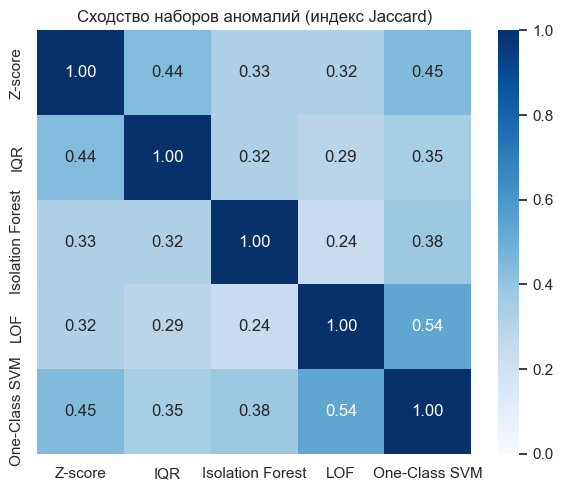

Число объектов по количеству методов (из 3: IF, LOF, OCSVM), которые их пометили:
0    2557
1     107
2      86
3      50

Все три метода: 50 | хотя бы два: 136 | ровно один: 107


In [18]:
# Пересечение наборов: матрица Jaccard и число объектов, отмеченных несколькими методами
names = list(flags.columns)
J = pd.DataFrame([[jaccard(flags[a].values, flags[b].values) for b in names] for a in names], index=names, columns=names)
plt.figure(figsize=(7, 5.5))
sns.heatmap(J, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Сходство наборов аномалий (индекс Jaccard)")
plt.show()

models3 = ["Isolation Forest", "LOF", "One-Class SVM"]
n_methods = flags[models3].sum(axis=1)
print("Число объектов по количеству методов (из 3: IF, LOF, OCSVM), которые их пометили:")
print(n_methods.value_counts().sort_index().to_string())
print(f"\nВсе три метода: {(n_methods == 3).sum()} | хотя бы два: {(n_methods >= 2).sum()} | ровно один: {(n_methods == 1).sum()}")

In [19]:
# Насколько найденные объекты отличаются от основной массы: расстояние до «центра» в масштабированном пространстве
dist_center = np.linalg.norm(X_rs - np.median(X_rs, axis=0), axis=1)
rows = []
for name in names:
    f = flags[name].values
    rows.append({"Метод": name, "медиана расстояния: аномалии": np.median(dist_center[f]),
                 "медиана расстояния: остальные": np.median(dist_center[~f]),
                 "отношение": np.median(dist_center[f]) / np.median(dist_center[~f])})
sep = pd.DataFrame(rows).set_index("Метод").round(2)
sep

,медиана расстояния: аномалии,медиана расстояния: остальные,отношение
Метод,,,
Z-score,4.42,2.26,1.95
IQR,3.85,2.23,1.73
Isolation Forest,4.40,2.26,1.95
LOF,3.65,2.26,1.62
One-Class SVM,3.97,2.26,1.76


**Как читать:** отношение показывает, во сколько раз помеченные объекты в среднем дальше от центра данных, чем остальные. У глобальных методов (Z-score, IQR, Isolation Forest) оно обычно выше, у LOF — ниже: LOF отмечает и объекты, не слишком далёкие от центра, но необычные *локально*. Низкое отношение — не недостаток, а следствие другой постановки задачи.

In [20]:
# Влияние масштабирования: LOF и One-Class SVM на данных без масштабирования, с StandardScaler и с RobustScaler
def lof_flag_of(X, k=K_LOF):
    return LocalOutlierFactor(n_neighbors=k, contamination=CONT).fit_predict(X) == -1
def oc_flag_of(X):
    return OneClassSVM(nu=NU, gamma="scale").fit(X).predict(X) == -1

X_std = StandardScaler().fit_transform(X_imp)
X_none = X_imp.values
rows = []
for nm, fn in (("LOF", lof_flag_of), ("One-Class SVM", oc_flag_of)):
    f_rs, f_std, f_none = fn(X_rs), fn(X_std), fn(X_none)
    rows.append({"Метод": nm, "Jaccard Robust vs Standard": round(jaccard(f_rs, f_std), 2),
                 "Jaccard Robust vs без масштаба": round(jaccard(f_rs, f_none), 2),
                 "помечено без масштаба": int(f_none.sum())})
f_iso_none = IsolationForest(n_estimators=300, contamination=CONT, random_state=RANDOM_STATE).fit(X_none).predict(X_none) == -1
rows.append({"Метод": "Isolation Forest", "Jaccard Robust vs Standard": "—",
             "Jaccard Robust vs без масштаба": round(jaccard(iso_flag, f_iso_none), 2), "помечено без масштаба": int(f_iso_none.sum())})
pd.DataFrame(rows).set_index("Метод")

,Jaccard Robust vs Standard,Jaccard Robust vs без масштаба,помечено без масштаба
Метод,,,
LOF,0.72,0.27,140
One-Class SVM,0.67,0.30,139
Isolation Forest,—,1.00,140


**Как читать:** Isolation Forest не зависит от линейного масштабирования: порог каждого разреза выбирается равномерно между минимумом и максимумом признака, поэтому при том же `random_state` набор аномалий совпал полностью (Jaccard 1.00). Для LOF и One-Class SVM масштаб критичен: без него признаки с большими числами (площадь участка) полностью определяют расстояния, и результат сильно меняется (Jaccard около 0.3); разница между StandardScaler и RobustScaler меньше, но заметна.

In [21]:
# Вариант с ценой в признаках: насколько меняется набор аномалий, если добавить SalePrice как ещё один признак
price = df["SalePrice"].values.reshape(-1, 1)
X_with_price = RobustScaler().fit_transform(np.hstack([X_imp.values, price]))
rows = []
for nm, m in (("Isolation Forest", IsolationForest(n_estimators=300, contamination=CONT, random_state=RANDOM_STATE)),
              ("LOF", LocalOutlierFactor(n_neighbors=K_LOF, contamination=CONT)),
              ("One-Class SVM", OneClassSVM(nu=NU, gamma="scale"))):
    f = (m.fit_predict(X_with_price) == -1)
    rows.append({"Метод": nm, "Jaccard с основным набором (без цены)": round(jaccard(f, flags[nm].values), 2)})
pd.DataFrame(rows).set_index("Метод")

,Jaccard с основным набором (без цены)
Метод,
Isolation Forest,0.70
LOF,0.72
One-Class SVM,0.71


**Как читать:** если Jaccard заметно меньше 1, то добавление цены меняет, кого считать аномалией: к необычным *характеристикам* добавляются объекты с необычной *ценой*. Поэтому основной анализ строим без цены: он отвечает на вопрос «чем объект необычен как объект», а цену используем для интерпретации.

### Отдельный эксперимент: искусственно добавленные аномалии
**Это искусственный эксперимент**, а не оценка на реальных метках: мы сами добавляем в копию данных объекты, которые заведомо необычны, и проверяем, какие методы их находят. Типы искусственных аномалий:
- **глобальные** — один-два признака принимают экстремальные значения (за пределами нормального диапазона);
- **комбинационные** — каждое отдельное значение лежит в нормальном диапазоне (5–95 процентиль), но сочетание необычно: *маленькая площадь при шести спальнях*, *огромная площадь при одной спальне и одной ванной*, *новый дом с очень низкой энергоэффективностью*.

Добавляем 21 глобальный и 21 комбинационный объект, повторяем с 5 разными случайными наборами и усредняем. Исходные данные не изменяются: работаем с копией. В реальных данных тоже могут быть настоящие аномалии, поэтому абсолютные цифры нужно воспринимать как иллюстрацию, а не как точность методов.

In [22]:
def make_injected(base, seed):
    # Возвращает копию данных с добавленными искусственными аномалиями и метки типа (0 — исходный объект)
    rng = np.random.default_rng(seed)
    p5, p95 = base.quantile(0.05), base.quantile(0.95)
    med = base.median()
    new = []
    kinds = []
    # глобальные: 3 случайных признака становятся экстремальными (в 3–6 раз больше 95-го процентиля)
    for _ in range(21):
        row = base.iloc[rng.integers(len(base))].copy()
        for c in rng.choice(["GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea", "PropertyAge"], 2, replace=False):
            row[c] = p95[c] * rng.uniform(3, 6) + 1
        new.append(row); kinds.append("global")
    # комбинационные: все значения внутри 5–95 процентиля
    for i in range(21):
        row = base.iloc[rng.integers(len(base))].copy()
        t = i % 3
        if t == 0:      # маленькая площадь + много спален и ванных
            row["GrLivArea"], row["Bedrooms"], row["Bathrooms"] = p5["GrLivArea"], p95["Bedrooms"], p95["Bathrooms"]
        elif t == 1:    # большая площадь + одна спальня + одна ванная + нет подвала и гаража
            row["GrLivArea"], row["Bedrooms"], row["Bathrooms"], row["TotalBsmtSF"], row["GarageArea"] = p95["GrLivArea"], 1, 1, p5["TotalBsmtSF"], p5["GarageArea"]
        else:           # новый дом с очень низкой энергоэффективностью и низким качеством
            row["PropertyAge"], row["EnergyEfficiency"], row["OverallQual"] = p5["PropertyAge"], p5["EnergyEfficiency"], p5["OverallQual"]
        new.append(row); kinds.append("combo")
    aug = pd.concat([base, pd.DataFrame(new)], ignore_index=True)
    labels = np.array(["normal"] * len(base) + kinds)
    return aug, labels

def detect_all(aug):
    # Запускаем все 5 методов на данных с искусственными аномалиями; возвращаем (флаги, оценки)
    Zs = (aug - aug.mean()) / aug.std()
    zf = (Zs.abs() > 3).any(axis=1).values
    q1, q3 = aug.quantile(0.25), aug.quantile(0.75); i = q3 - q1
    qf = ((aug < q1 - 1.5 * i) | (aug > q3 + 1.5 * i)).any(axis=1).values
    Xs = RobustScaler().fit_transform(aug)
    iso_m = IsolationForest(n_estimators=300, contamination=CONT, random_state=RANDOM_STATE).fit(Xs)
    lof_m = LocalOutlierFactor(n_neighbors=K_LOF, contamination=CONT)
    lof_f = lof_m.fit_predict(Xs) == -1
    oc_m = OneClassSVM(nu=NU, gamma="scale").fit(Xs)
    flags_ = {"Z-score": zf, "IQR": qf, "Isolation Forest": iso_m.predict(Xs) == -1,
              "LOF": lof_f, "One-Class SVM": oc_m.predict(Xs) == -1}
    scores_ = {"Z-score": Zs.abs().max(axis=1).values, "IQR": None,
               "Isolation Forest": -iso_m.score_samples(Xs), "LOF": -lof_m.negative_outlier_factor_,
               "One-Class SVM": -oc_m.decision_function(Xs)}
    return flags_, scores_

recs, aucs = [], []
for seed in range(5):
    aug, lab = make_injected(X_imp, seed)
    fl, sc = detect_all(aug)
    for nm, f in fl.items():
        for kind in ("global", "combo"):
            recs.append({"seed": seed, "Метод": nm, "Тип": kind, "recall": f[lab == kind].mean()})
        recs.append({"seed": seed, "Метод": nm, "Тип": "доля помеченных среди обычных", "recall": f[lab == "normal"].mean()})
    for nm, s in sc.items():
        if s is not None:
            for kind in ("global", "combo"):
                mask = (lab == kind) | (lab == "normal")
                aucs.append({"seed": seed, "Метод": nm, "Тип": kind, "AUC": roc_auc_score(lab[mask] == kind, s[mask])})
rec = pd.DataFrame(recs).groupby(["Метод", "Тип"])["recall"].mean().unstack().round(2)
rec = rec.loc[["Z-score", "IQR", "Isolation Forest", "LOF", "One-Class SVM"], ["global", "combo", "доля помеченных среди обычных"]]
rec.columns = ["Найдено глобальных (доля)", "Найдено комбинационных (доля)", "Ложно помечено среди обычных (доля)"]
print("Эксперимент на ИСКУССТВЕННЫХ аномалиях (метки известны по построению), среднее по 5 повторам:")
rec

Эксперимент на ИСКУССТВЕННЫХ аномалиях (метки известны по построению), среднее по 5 повторам:


,Найдено глобальных (доля),Найдено комбинационных (доля),Ложно помечено среди обычных (доля)
Метод,,,
Z-score,1.0,0.02,0.03
IQR,1.0,0.07,0.10
Isolation Forest,1.0,0.16,0.04
LOF,1.0,0.85,0.04
One-Class SVM,1.0,0.30,0.04


In [23]:
auc_tab = pd.DataFrame(aucs).groupby(["Метод", "Тип"])["AUC"].mean().unstack().round(3)
auc_tab.columns = ["AUC: комбинационные", "AUC: глобальные"]
print("ROC-AUC по anomaly score (ранжирование искусственных аномалий среди обычных; только для методов с оценкой):")
auc_tab[["AUC: глобальные", "AUC: комбинационные"]]

ROC-AUC по anomaly score (ранжирование искусственных аномалий среди обычных; только для методов с оценкой):


,AUC: глобальные,AUC: комбинационные
Метод,,
Isolation Forest,0.992,0.851
LOF,1.000,0.976
One-Class SVM,1.000,0.907
Z-score,0.999,0.645


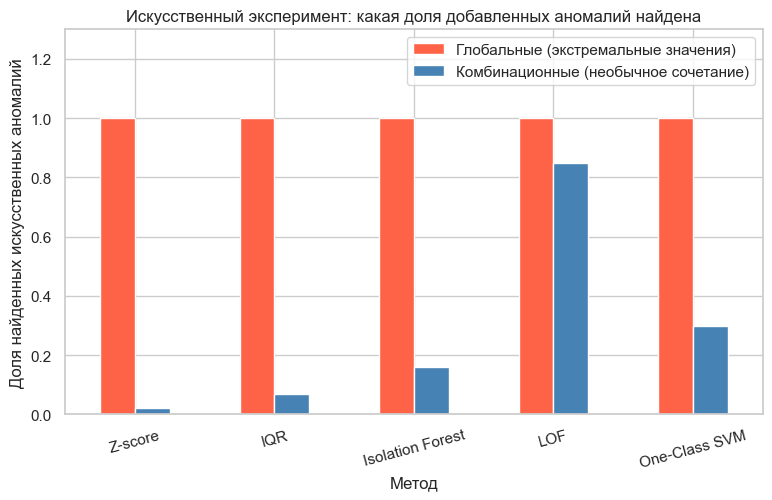

In [24]:
rec.iloc[:, :2].plot(kind="bar", figsize=(9, 5), rot=15, color=["tomato", "steelblue"])
plt.title("Искусственный эксперимент: какая доля добавленных аномалий найдена")
plt.xlabel("Метод")
plt.ylabel("Доля найденных искусственных аномалий")
plt.ylim(0, 1.3)
plt.legend(["Глобальные (экстремальные значения)", "Комбинационные (необычное сочетание)"], loc="upper right")
plt.show()

**Как читать:** если Z-score и IQR находят почти все глобальные аномалии, но почти не находят комбинационные, это подтверждает их ограничение: они смотрят на признаки по одному. Многомерные методы находят и необычные сочетания. Эти результаты относятся к *искусственным* объектам и конкретной схеме их создания; они не говорят о «точности» методов на реальных данных.

## Визуализация
PCA используется **только** для картинки — это проекция на две оси, а не доказательство того, что объект аномален: объект, выглядящий «внутри облака» на плоскости, может быть необычен в других измерениях.

Две компоненты PCA сохраняют 42.7% дисперсии


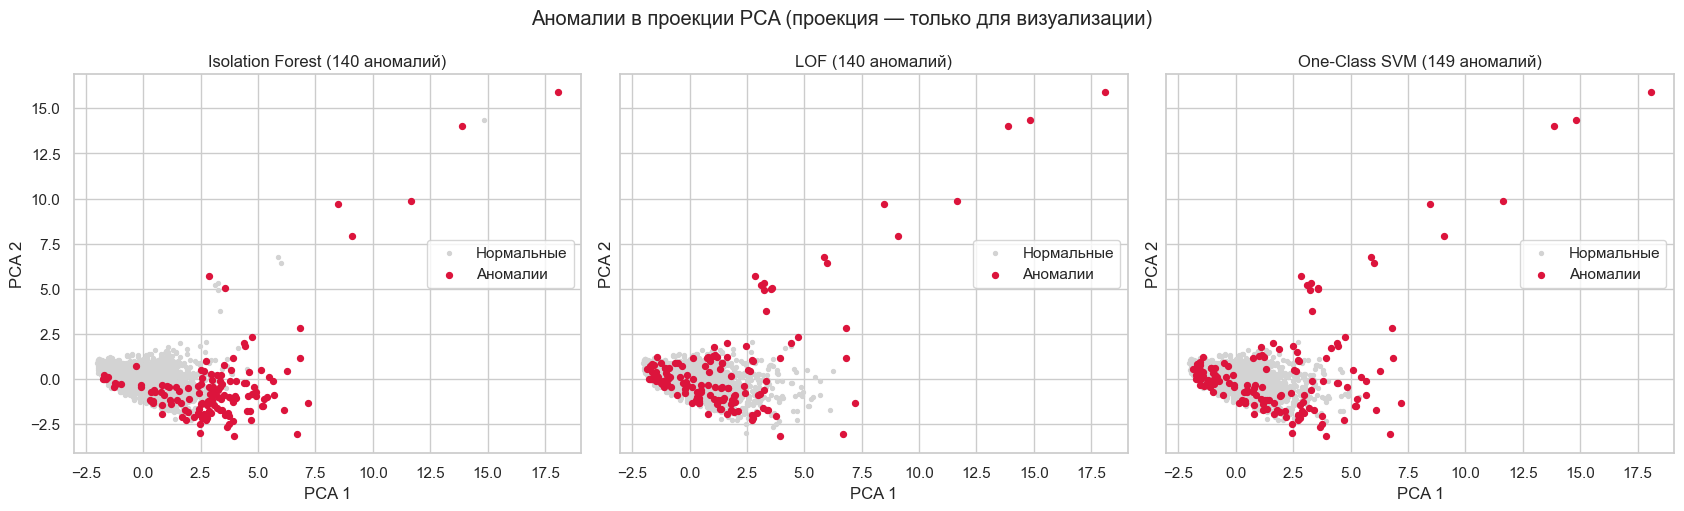

In [25]:
# PCA-проекция: нормальные объекты и аномалии для каждого метода
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z2 = pca.fit_transform(X_rs)
print(f"Две компоненты PCA сохраняют {pca.explained_variance_ratio_.sum() * 100:.1f}% дисперсии")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True, sharey=True)
for ax, nm in zip(axes, models3):
    f = flags[nm].values
    ax.scatter(Z2[~f, 0], Z2[~f, 1], s=8, c="lightgray", label="Нормальные")
    ax.scatter(Z2[f, 0], Z2[f, 1], s=18, c="crimson", label="Аномалии")
    ax.set_title(f"{nm} ({f.sum()} аномалий)")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.legend(loc="center right")
plt.suptitle("Аномалии в проекции PCA (проекция — только для визуализации)")
plt.tight_layout()
plt.show()

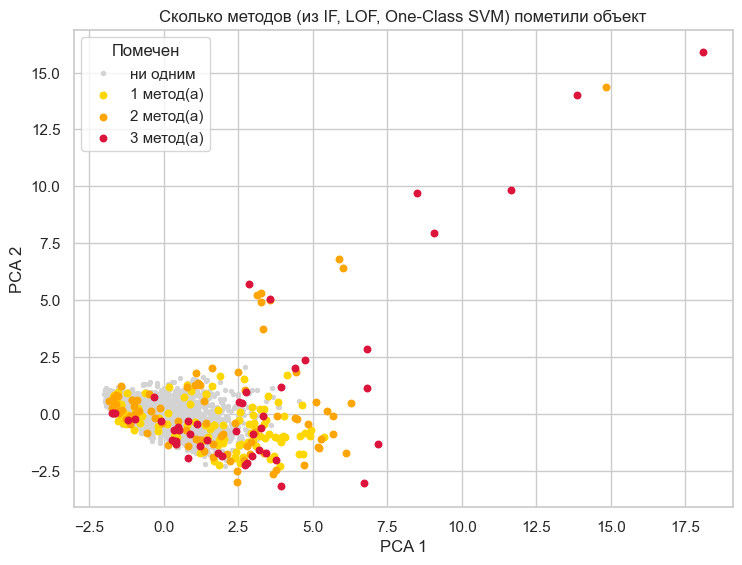

In [26]:
# Объекты, отмеченные несколькими методами одновременно
fig, ax = plt.subplots(figsize=(8.5, 6.2))
colors = {0: "lightgray", 1: "gold", 2: "orange", 3: "crimson"}
for k in (0, 1, 2, 3):
    mk = (n_methods == k).values
    ax.scatter(Z2[mk, 0], Z2[mk, 1], s=8 if k == 0 else 22, c=colors[k], label=f"{k} метод(а)" if k else "ни одним", zorder=k + 1)
ax.set_title("Сколько методов (из IF, LOF, One-Class SVM) пометили объект")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.legend(title="Помечен")
plt.show()

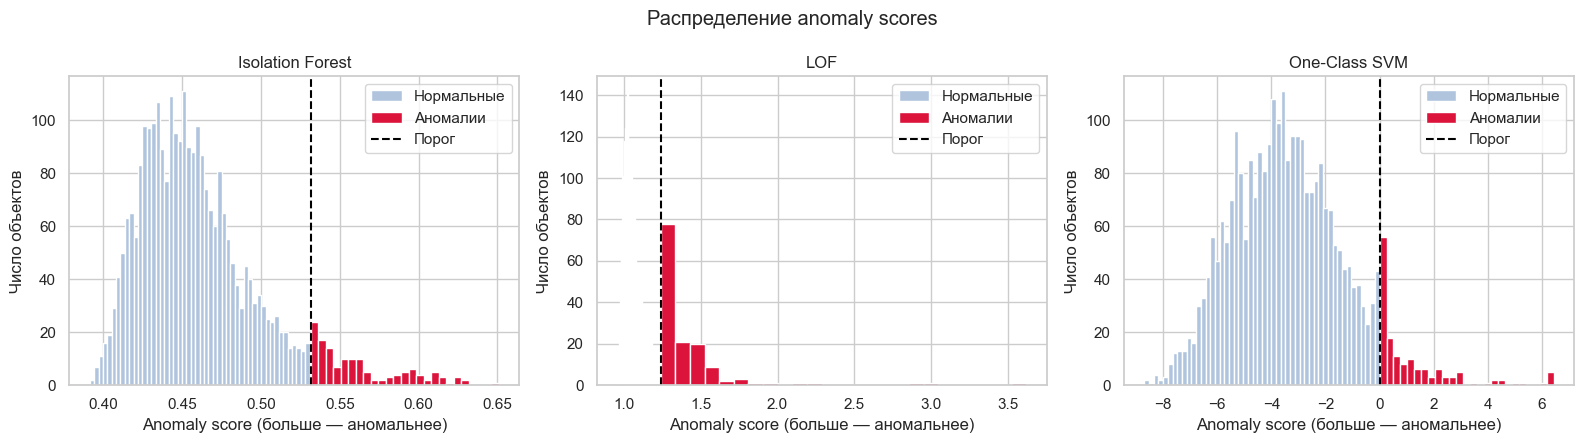

In [27]:
# Anomaly scores трёх методов: гистограммы с порогом (минимальный score среди помеченных объектов)
scores = {"Isolation Forest": iso_score, "LOF": lof_score, "One-Class SVM": oc_score}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nm, s) in zip(axes, scores.items()):
    f = flags[nm].values
    ax.hist(s[~f], bins=50, color="lightsteelblue", label="Нормальные")
    ax.hist(s[f], bins=25, color="crimson", label="Аномалии")
    ax.axvline(s[f].min(), color="black", ls="--", label="Порог")
    ax.set_title(nm)
    ax.set_xlabel("Anomaly score (больше — аномальнее)")
    ax.set_ylabel("Число объектов")
    ax.legend()
plt.suptitle("Распределение anomaly scores")
plt.tight_layout()
plt.show()

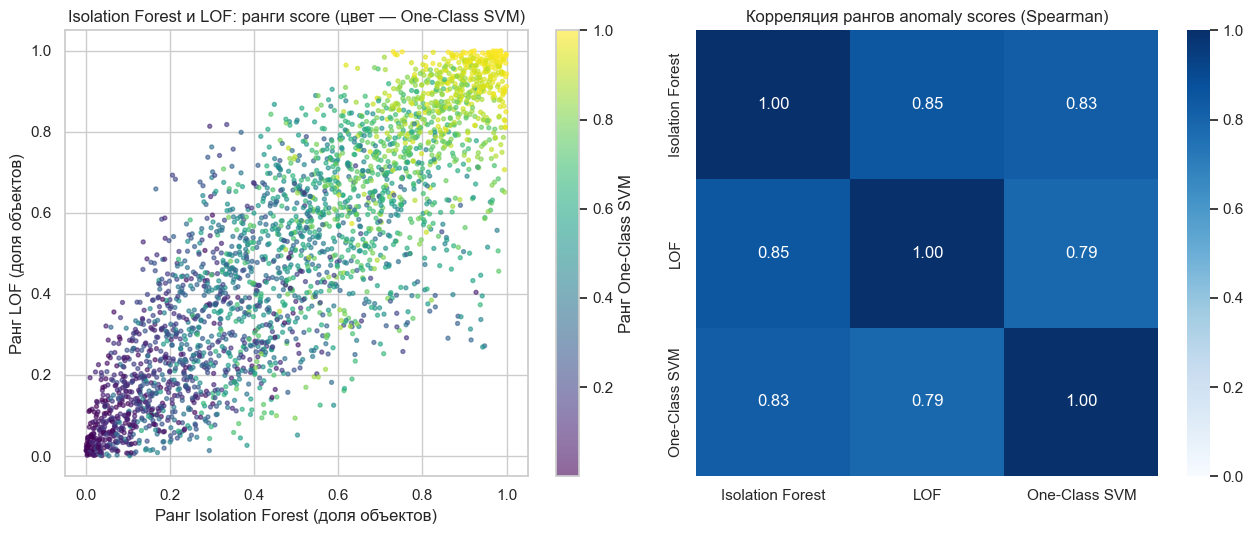

In [28]:
# Согласие методов по ранжированию: ранги scores (чем правее/выше, тем аномальнее)
ranks = pd.DataFrame(scores).rank(pct=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sc = axes[0].scatter(ranks["Isolation Forest"], ranks["LOF"], c=ranks["One-Class SVM"], cmap="viridis", s=8, alpha=0.6)
axes[0].set_title("Isolation Forest и LOF: ранги score (цвет — One-Class SVM)")
axes[0].set_xlabel("Ранг Isolation Forest (доля объектов)")
axes[0].set_ylabel("Ранг LOF (доля объектов)")
plt.colorbar(sc, ax=axes[0], label="Ранг One-Class SVM")
sns.heatmap(pd.DataFrame(scores).corr(method="spearman"), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Корреляция рангов anomaly scores (Spearman)")
plt.tight_layout()
plt.show()

## Исследование найденных объектов
Берём объекты, отмеченные **всеми тремя** алгоритмами (наиболее надёжные кандидаты), и несколько объектов, отмеченных **только одним** методом (чтобы увидеть, чем отличаются типы аномалий). Для каждого показываем значения, процентили относительно данных, что выглядит необычно, какими методами он помечен, и проверяем, не связана ли аномалия с пропусками. Объекты не называются ошибочными: формулировка «нетипичен по выбранным признакам, требует дополнительной проверки».

In [29]:
pct = X_imp.rank(pct=True) * 100                       # процентиль каждого значения в данных
robust_z = pd.DataFrame(X_rs, columns=features, index=df.index)   # отклонение в единицах IQR от медианы

consensus_score = ranks.mean(axis=1)                    # средний ранг по трём методам (0..1)
all3 = df.index[(n_methods == 3).values]
top_all3 = consensus_score.loc[all3].sort_values(ascending=False).head(5).index

def describe(i):
    row = df.loc[i]
    methods = [nm for nm in names if flags.loc[i, nm]]
    unusual = robust_z.loc[i].abs().sort_values(ascending=False).head(3).index
    parts = []
    for f in unusual:
        direction = "выше" if robust_z.loc[i, f] > 0 else "ниже"
        parts.append(f"{f} = {row[f]:g} ({direction} типичного, процентиль {pct.loc[i, f]:.0f})")
    imputed = [f for f in features if imputed_mask.loc[i, f]]
    print(f"Id {row['Id']} | {row['PropertyType']}, {row['Neighborhood']} | SalePrice = {row['SalePrice']:,.0f} "
          f"(процентиль цены {df['SalePrice'].rank(pct=True)[i] * 100:.0f})")
    print("  Помечен методами:", ", ".join(methods))
    print("  Нетипичен по:", "; ".join(parts))
    print("  Значения, заполненные медианой (были пропущены):", imputed if imputed else "нет")
    print()

print("=== Объекты, помеченные всеми тремя методами (топ-5 по среднему рангу) ===")
for i in top_all3:
    describe(i)

=== Объекты, помеченные всеми тремя методами (топ-5 по среднему рангу) ===
Id 2601 | Villa, Hillcrest | SalePrice = 1,277,600 (процентиль цены 99)
  Помечен методами: Z-score, IQR, Isolation Forest, LOF, One-Class SVM
  Нетипичен по: LotArea = 2949 (выше типичного, процентиль 99); GrLivArea = 329 (выше типичного, процентиль 99); Bedrooms = 8 (выше типичного, процентиль 99)
  Значения, заполненные медианой (были пропущены): нет

Id 1895 | House, OldTown | SalePrice = 891,300 (процентиль цены 95)
  Помечен методами: Z-score, IQR, Isolation Forest, LOF, One-Class SVM
  Нетипичен по: LotArea = 11197 (выше типичного, процентиль 100); GarageArea = 67 (выше типичного, процентиль 96); PropertyAge = 68 (выше типичного, процентиль 94)
  Значения, заполненные медианой (были пропущены): ['EnergyEfficiency']

Id 2376 | Villa, Riverside | SalePrice = 2,127,800 (процентиль цены 100)
  Помечен методами: Z-score, IQR, Isolation Forest, LOF, One-Class SVM
  Нетипичен по: GrLivArea = 523 (выше типичного,

In [30]:
# Таблица исходных характеристик этих объектов рядом с медианой датасета
tab = df.loc[top_all3, ["Id", "PropertyType", "Neighborhood"] + features + ["SalePrice"]].set_index("Id").T
tab["Медиана датасета"] = list(["—", "—"]) + list(X_imp.median().round(1)) + [df["SalePrice"].median()]
tab

Id,2601,1895,2376,1808,1481,Медиана датасета
PropertyType,Villa,House,Villa,Duplex,Villa,—
Neighborhood,Hillcrest,OldTown,Riverside,Midtown,Midtown,—
GrLivArea,329,185,523,157,538,120.0
LotArea,2949.0,11197.0,1911.0,5822.0,1353.0,224.0
TotalBsmtSF,141.0,145.0,415.0,0.0,449.0,54.0
Bedrooms,8,5,8,5,8,3.0
Bathrooms,5,2,4,2,6,2.0
OverallQual,4,4,7,9,7,6.0
PropertyAge,57,68,0,53,46,35.0
GarageArea,22.0,67.0,44.0,68.0,36.0,25.0


In [31]:
# Объекты, помеченные только одним методом: примеры разных типов аномалий
for nm in ("LOF", "Isolation Forest", "One-Class SVM"):
    only = df.index[(flags[nm].values) & (n_methods.values == 1)]
    top = ranks.loc[only, nm].sort_values(ascending=False).head(2).index
    print(f"=== Помечены только методом {nm} (всего таких объектов: {len(only)}) ===")
    for i in top:
        describe(i)

=== Помечены только методом LOF (всего таких объектов: 34) ===
Id 1442 | Apartment, Downtown | SalePrice = 1,936,400 (процентиль цены 100)
  Помечен методами: IQR, LOF
  Нетипичен по: GrLivArea = 274 (выше типичного, процентиль 98); PropertyAge = 0 (ниже типичного, процентиль 3); OverallQual = 4 (ниже типичного, процентиль 10)
  Значения, заполненные медианой (были пропущены): нет

Id 310 | Apartment, Riverside | SalePrice = 1,084,100 (процентиль цены 98)
  Помечен методами: LOF
  Нетипичен по: GrLivArea = 242 (выше типичного, процентиль 96); OverallQual = 9 (выше типичного, процентиль 96); GarageArea = 42 (выше типичного, процентиль 69)
  Значения, заполненные медианой (были пропущены): ['EnergyEfficiency']

=== Помечены только методом Isolation Forest (всего таких объектов: 55) ===
Id 2530 | Villa, Industrial | SalePrice = 945,800 (процентиль цены 96)
  Помечен методами: Z-score, IQR, Isolation Forest
  Нетипичен по: GrLivArea = 361 (выше типичного, процентиль 100); LotArea = 1628 (в

### Что отличает локальную аномалию: сравнение с ближайшими соседями
Объект, помеченный *только* LOF, может не выглядеть экстремальным относительно всех данных. Посмотрим на него глазами LOF: сравним его значения со значениями его `n_neighbors` ближайших соседей.

In [32]:
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=K_LOF + 1).fit(X_rs)

only_lof = df.index[flags["LOF"].values & (n_methods.values == 1)]
i = ranks.loc[only_lof, "LOF"].idxmax()                 # самый «LOF-аномальный» объект среди помеченных только LOF
dist, idx = nn.kneighbors(X_rs[[i]])
neigh = idx[0][1:]                                      # ближайшие соседи (без самого объекта)

view = pd.DataFrame({"объект": X_imp.loc[i], "медиана соседей": X_imp.iloc[neigh].median(),
                     "медиана всех данных": X_imp.median()})
view["отличие от соседей, в IQR"] = ((view["объект"] - view["медиана соседей"]) / iqr).round(2)
view["отличие от всех данных, в IQR"] = ((view["объект"] - view["медиана всех данных"]) / iqr).round(2)
print(f"Id {df.loc[i, 'Id']} ({df.loc[i, 'PropertyType']}, {df.loc[i, 'Neighborhood']}), LOF-score = {lof_score[i]:.2f}")

# Локальная плотность: расстояние до 20-го соседа у объекта и у его соседей
kdist = nn.kneighbors(X_rs, return_distance=True)[0][:, -1]
print(f"Расстояние до {K_LOF}-го соседа: у объекта {kdist[i]:.2f}, в среднем у его соседей {kdist[neigh].mean():.2f} "
      f"(во сколько раз объект «разреженнее»: {kdist[i] / kdist[neigh].mean():.2f})")
view.round(1)

Id 1442 (Apartment, Downtown), LOF-score = 1.43
Расстояние до 20-го соседа: у объекта 2.54, в среднем у его соседей 1.83 (во сколько раз объект «разреженнее»: 1.39)


,объект,медиана соседей,медиана всех данных,"отличие от соседей, в IQR","отличие от всех данных, в IQR"
GrLivArea,274.0,159.5,120.0,1.6,2.1
LotArea,0.0,200.0,224.0,-0.4,-0.5
TotalBsmtSF,0.0,44.5,54.0,-0.5,-0.6
Bedrooms,4.0,4.0,3.0,0.0,0.5
Bathrooms,3.0,3.0,2.0,0.0,0.5
OverallQual,4.0,5.0,6.0,-0.5,-1.0
PropertyAge,0.0,4.5,35.0,-0.2,-1.2
GarageArea,24.0,25.0,25.0,-0.0,-0.0
DistanceToCenter,0.3,2.2,5.6,-0.3,-0.9
EnergyEfficiency,99.0,92.0,88.0,0.4,0.6


**Как читать:** значение `kdist` у объекта заметно больше, чем у его соседей: вокруг него «пусто» по сравнению с плотностью соседних областей. Именно это и фиксирует LOF — локальную разреженность, которую глобальные методы (IQR, Isolation Forest) не видят, если отдельные значения не экстремальны.

In [33]:
# Объекты с нарушением логики (комнат меньше, чем спален): какими методами они помечены?
bad = df.index[(df["Rooms"] < df["Bedrooms"]).values]
chk = df.loc[bad, ["Id", "PropertyType", "GrLivArea", "Rooms", "Bedrooms", "Bathrooms", "SalePrice"]].copy()
for nm in names:
    chk[nm] = flags.loc[bad, nm].values
chk

,Id,PropertyType,GrLivArea,Rooms,Bedrooms,Bathrooms,SalePrice,Z-score,IQR,Isolation Forest,LOF,One-Class SVM
11,925,House,148,4,12,2,634600,True,True,False,True,True
1257,2341,Apartment,66,6,10,3,368700,True,True,False,True,True
1563,753,House,138,6,10,2,581800,True,True,False,True,True
2540,1084,House,136,4,9,3,333900,True,True,False,True,True


**Как читать:** это объекты с логической несогласованностью (спален больше, чем комнат; на 66–148 м² заявлено 9–12 спален). Это *вероятные ошибки ввода или нарушения целостности данных*, но утверждать это без проверки по источнику нельзя: объект «требует дополнительной проверки». Алгоритмы нашли их не все (результат зависит от метода), поэтому простые проверки логики данных полезно дополнять, а не заменять ими алгоритмы.

### Проверка: не вызваны ли аномалии ошибками, пропусками или обработкой
Сравним долю объектов с заполненными пропусками и нарушениями простых логических проверок среди аномалий и среди остальных.

In [34]:
had_imputation = imputed_mask.any(axis=1).values
logic = pd.DataFrame({
    "Rooms < Bedrooms": (df["Rooms"] < df["Bedrooms"]),
    "Ремонт раньше постройки": (df["YearRenovated"] < df["YearBuilt"]),
    "Floor > TotalFloors": (df["Floor"] > df["TotalFloors"]),
    "Гараж: 0 машин, но площадь > 0": ((df["GarageCars"] == 0) & (df["GarageArea"] > 0)),
}).any(axis=1).values

rows = []
for nm in models3:
    f = flags[nm].values
    rows.append({"Метод": nm,
                 "доля с заполненными пропусками: аномалии, %": round(had_imputation[f].mean() * 100, 1),
                 "доля с заполненными пропусками: остальные, %": round(had_imputation[~f].mean() * 100, 1),
                 "нарушения логики: аномалии": int(logic[f].sum()),
                 "нарушения логики: остальные": int(logic[~f].sum())})
pd.DataFrame(rows).set_index("Метод")

,"доля с заполненными пропусками: аномалии, %","доля с заполненными пропусками: остальные, %",нарушения логики: аномалии,нарушения логики: остальные
Метод,,,,
Isolation Forest,23.6,35.3,0,4
LOF,31.4,34.9,4,0
One-Class SVM,29.5,35.0,4,0


**Как читать:** если доля объектов с заполненными пропусками среди аномалий близка к доле среди остальных, то аномалии не объясняются просто заполнением медианой. Нулевые нарушения логических проверок означают, что найденные объекты — не очевидные ошибки ввода, а необычные по сочетанию характеристик (это всё же не доказательство отсутствия ошибок: проверять нужно по источнику данных).

In [35]:
# Цена и тип недвижимости как дополнительная интерпретация (цена в алгоритмы не передавалась)
cons = (n_methods >= 2).values
cmp = pd.DataFrame({
    "Объектов": [cons.sum(), (~cons).sum()],
    "Медианная цена": [df.loc[cons, "SalePrice"].median(), df.loc[~cons, "SalePrice"].median()],
    "Медианная площадь": [df.loc[cons, "GrLivArea"].median(), df.loc[~cons, "GrLivArea"].median()],
}, index=["Отмечены ≥ 2 методами", "Остальные"]).round(0)
print(cmp.to_string())
print()
print("Тип недвижимости, % (аномалии ≥ 2 методов / все объекты):")
print(pd.DataFrame({"аномалии": df.loc[cons, "PropertyType"].value_counts(normalize=True) * 100,
                    "все": df["PropertyType"].value_counts(normalize=True) * 100}).round(1).fillna(0).to_string())

# Сохраняем результаты
out = df[["Id", "PropertyType", "Neighborhood", "SalePrice"] + features].copy()
for nm in names:
    out[f"flag_{nm}"] = flags[nm].values
out["n_methods_3"] = n_methods.values
out["consensus_rank"] = consensus_score.values
out.sort_values("consensus_rank", ascending=False).to_csv(OUT_DIR / "anomaly_results.csv", index=False)
comp.to_csv(OUT_DIR / "methods_comparison.csv")
print("\nСохранено:", OUT_DIR / "anomaly_results.csv")

                       Объектов  Медианная цена  Медианная площадь
Отмечены ≥ 2 методами       136        593200.0              176.0
Остальные                  2664        432100.0              119.0

Тип недвижимости, % (аномалии ≥ 2 методов / все объекты):
              аномалии   все
PropertyType                
Apartment         23.5  32.3
Duplex             8.1  10.3
House             42.6  37.2
Penthouse          0.7   0.1
Townhouse          9.6  16.9
Villa             15.4   3.1

Сохранено: ../outputs/anomaly_detection/anomaly_results.csv


## Интерпретация результатов
**Наблюдение** — то, что посчитано; **гипотеза** — объяснение, которое стоит проверять отдельно. Аномалия = «нетипичный по выбранным признакам», а не «ошибка».

**1. Какие типы аномалий обнаружены (наблюдения).**
- *Глобальные экстремумы:* очень большие дома и виллы (например, площадь 523 и 538 м² — 100-й процентиль, 8 спален; участок 11 197 м² у дома в OldTown). Эти объекты помечены **всеми пятью** методами. Всего три основных метода одновременно выбрали 50 объектов, хотя бы два — 136.
- *Логически несогласованные объекты:* 4 объекта, у которых **комнат меньше, чем спален** (9–12 спален при 66–148 м², например квартира 66 м² с 10 спальнями). Это вероятные ошибки ввода или нарушения целостности данных (гипотеза — проверять по источнику). Их пометили Z-score, IQR, LOF и One-Class SVM, **но не Isolation Forest**.
- *Локальные аномалии:* 34 объекта помечены только LOF. Пример — квартира в Downtown (274 м², новая постройка, качество 4): она не экстремальна по отдельным признакам, но расстояние до её 20-го соседа в 1.39 раза больше, чем у самих соседей, то есть вокруг неё локально «пусто». Эффект умеренный, это пример логики LOF, а не сильная аномалия.

**2. Глобальные и локальные аномалии.** Глобальные удалены от всех данных (наблюдение: отношение медианных расстояний до центра у Isolation Forest 1.95, у LOF 1.62). Локальные необычны только на фоне своих соседей, поэтому глобальные методы их часто пропускают. Искусственный эксперимент это подтверждает (п. 5).

**3. Почему алгоритмы расходятся (наблюдения + гипотеза).**
- Совпадение наборов умеренное: Jaccard IF–LOF 0.24, IF–OCSVM 0.38, LOF–OCSVM 0.54; 107 объектов помечены ровно одним методом.
- Но ранжирование объектов по anomaly score согласовано сильно (корреляция Спирмена 0.79–0.85): методы в основном согласны, *кто необычнее*, а расходятся из-за **порога**: мы задали одинаковую долю 5%, и объекты у границы попадают в набор случайно.
- *Гипотеза:* различия отражают разные определения «необычного» (изоляция, локальная плотность, граница вокруг массы).

**4. Влияние масштаба и параметров (наблюдения).**
- Масштабирование: Isolation Forest не зависит от линейного масштаба (Jaccard 1.00); у LOF и One-Class SVM без масштабирования результат сильно меняется (Jaccard с RobustScaler около 0.27 и 0.30); StandardScaler и RobustScaler расходятся меньше (0.72 и 0.67).
- `contamination` у Isolation Forest лишь сдвигает порог: наборы вложены (28 → 56 → 140 → 280 объектов). У LOF `n_neighbors` меняет состав: Jaccard между 10 и 100 соседями всего 0.44, между 35 и 50 — 0.88. У One-Class SVM `nu` задаёт долю (64/149/279 объектов при nu 0.02/0.05/0.10), а `gamma` меняет состав (Jaccard с основной настройкой 0.35–0.66).
- Случайность Isolation Forest: при смене `random_state` Jaccard в среднем 0.77; 105 объектов попали во все 5 запусков, 181 — хотя бы в один.
- Если добавить цену в признаки, наборы меняются (Jaccard 0.70–0.72): поэтому основной анализ без цены.

**5. Искусственный эксперимент (метки известны по построению, поэтому метрики допустимы; это не оценка на реальных аномалиях).**
- Глобальные искусственные аномалии находят все методы (доля 1.00).
- Комбинационные (каждое значение обычно, сочетание необычно): LOF 0.85, One-Class SVM 0.30, Isolation Forest 0.16, IQR 0.07, Z-score 0.02. ROC-AUC по score: LOF 0.976, One-Class SVM 0.907, Isolation Forest 0.851, Z-score 0.645.
- Ложно помеченных среди обычных объектов: 3–4% у большинства методов, у IQR около 10%.
- *Оговорка:* результат зависит от того, как мы сконструировали комбинации и от выбранных параметров; он иллюстрирует **типы** аномалий, а не «лучший метод вообще». Нельзя на этом основании сказать, что LOF объективно лучше.

**6. Не объясняются ли аномалии пропусками (наблюдение).** Доля объектов с заполненными пропусками среди аномалий (24–31%) не выше, чем среди остальных (35%) — аномалии не порождены медианным заполнением.

**7. Что полезно для анализа недвижимости.** Список объектов, помеченных несколькими методами, — кандидаты на ручную проверку; отдельный пункт — 4 логически несогласованных объекта (их стоит проверить по источнику и, возможно, исправить до построения моделей). Среди объектов, помеченных ≥ 2 методами, медианная площадь 176 м² против 119 м² у остальных, медианная цена 593 тыс. против 432 тыс. (цена в алгоритмы не передавалась) и больше вилл (15% против 3% в данных). *Гипотеза:* алгоритмы чаще отмечают крупные и дорогие объекты, потому что они редки; это не значит, что они «ошибочные».

**8. Ограничения.** Данные синтетические; доля аномалий 5% — допущение, а не знание; истинных меток нет; пропуски заполнены медианой; признаки выбраны исследователем (без бинарных и категориальных); PCA-проекция показывает лишь 42.7% дисперсии; результаты чувствительны к масштабу и параметрам; искусственный эксперимент зависит от способа конструирования аномалий.


## Общие выводы
Автоматическая часть формируется по реальным результатам выше.

In [36]:
print(f"Объектов после очистки: {len(df)}; признаков для поиска аномалий: {len(features)} (SalePrice и Id в алгоритмы не передавались).")
print("Помечено объектов (ожидаемая доля аномалий задана 5%):", flags.sum().to_dict())
print(f"Отмечено всеми тремя методами (IF, LOF, OCSVM): {(n_methods == 3).sum()}; хотя бы двумя: {(n_methods >= 2).sum()}; ровно одним: {(n_methods == 1).sum()}.")
print(f"Согласие методов (Jaccard): IF–LOF {J.loc['Isolation Forest', 'LOF']:.2f}, IF–OCSVM {J.loc['Isolation Forest', 'One-Class SVM']:.2f}, LOF–OCSVM {J.loc['LOF', 'One-Class SVM']:.2f}.")
print(f"Искусственный эксперимент — доля найденных комбинационных аномалий: " +
      ", ".join(f"{k} {v:.2f}" for k, v in rec.iloc[:, 1].items()) + ".")
print("Один метод нельзя назвать лучшим только потому, что он нашёл больше объектов: число помеченных задаётся параметрами.")

Объектов после очистки: 2800; признаков для поиска аномалий: 12 (SalePrice и Id в алгоритмы не передавались).
Помечено объектов (ожидаемая доля аномалий задана 5%): {'Z-score': 126, 'IQR': 278, 'Isolation Forest': 140, 'LOF': 140, 'One-Class SVM': 149}
Отмечено всеми тремя методами (IF, LOF, OCSVM): 50; хотя бы двумя: 136; ровно одним: 107.
Согласие методов (Jaccard): IF–LOF 0.24, IF–OCSVM 0.38, LOF–OCSVM 0.54.
Искусственный эксперимент — доля найденных комбинационных аномалий: Z-score 0.02, IQR 0.07, Isolation Forest 0.16, LOF 0.85, One-Class SVM 0.30.
Один метод нельзя назвать лучшим только потому, что он нашёл больше объектов: число помеченных задаётся параметрами.
